# LAB3 - Bài 3 (Trang 7): Neural Network trên MNIST với k-fold cross validation (k=10)
**Đinh Nhật Huyền Nhân - 6451071055 - CQ.64.CNTT**

In [1]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# a) Đọc bộ dữ liệu train, test của MNIST từ Keras
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
from tensorflow.keras.datasets import mnist
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("Đã đọc MNIST.")

Đinh Nhật Huyền Nhân - 6451071055


Đã đọc MNIST.


In [2]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# b) Kích thước tập train, test
print("train_images:", train_images.shape, "| train_labels:", train_labels.shape)
print("test_images :", test_images.shape, "| test_labels :", test_labels.shape)

Đinh Nhật Huyền Nhân - 6451071055
train_images: (60000, 28, 28) | train_labels: (60000,)
test_images : (10000, 28, 28) | test_labels : (10000,)


In [3]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# c) Chuẩn hóa pixel về [0,1]
train_images = train_images / 255.0
test_images = test_images / 255.0
print("Min/Max train:", train_images.min(), train_images.max())

Đinh Nhật Huyền Nhân - 6451071055
Min/Max train: 0.0 1.0


In [4]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# d) Hàm create_model: Neural Network tương tự câu 2 + biên dịch
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout, Input

def create_model():
    model = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.2),
        Dense(10, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

create_model().summary()

Đinh Nhật Huyền Nhân - 6451071055


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# e) Huấn luyện bằng k-fold cross validation (k=10), lưu mô hình sau mỗi fold
from sklearn.model_selection import KFold
tf.keras.utils.set_random_seed(42)
os.makedirs("models_bai3", exist_ok=True)

kfold = KFold(n_splits=10, shuffle=True, random_state=42)
models, accuracy_per_fold, loss_per_fold = [], [], []

for fold, (train_index, val_index) in enumerate(kfold.split(train_images), start=1):
    model = create_model()
    X_train_fold, X_val_fold = train_images[train_index], train_images[val_index]
    y_train_fold, y_val_fold = train_labels[train_index], train_labels[val_index]
    model.fit(X_train_fold, y_train_fold, epochs=5, batch_size=32,
              validation_data=(X_val_fold, y_val_fold), verbose=0)
    models.append(model)
    model.save(f"models_bai3/model_fold_{fold}.keras")
    loss, acc = model.evaluate(X_val_fold, y_val_fold, verbose=0)
    accuracy_per_fold.append(acc)
    loss_per_fold.append(loss)
    print(f"Fold {fold:2d}: loss = {loss:.4f} - accuracy = {acc:.4f}")

Đinh Nhật Huyền Nhân - 6451071055


Fold  1: loss = 0.0765 - accuracy = 0.9793


Fold  2: loss = 0.0941 - accuracy = 0.9723


Fold  3: loss = 0.0943 - accuracy = 0.9723


Fold  4: loss = 0.0826 - accuracy = 0.9765


Fold  5: loss = 0.1018 - accuracy = 0.9712


Fold  6: loss = 0.0842 - accuracy = 0.9767


Fold  7: loss = 0.0935 - accuracy = 0.9722


Fold  8: loss = 0.0837 - accuracy = 0.9728


Fold  9: loss = 0.0928 - accuracy = 0.9722


Fold 10: loss = 0.0750 - accuracy = 0.9747


In [6]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# f) Mean / Std của Accuracy và Loss
print(f"Mean Accuracy: {np.mean(accuracy_per_fold):.4f}")
print(f"Std Accuracy : {np.std(accuracy_per_fold):.4f}")
print(f"Mean Loss    : {np.mean(loss_per_fold):.4f}")
print(f"Std Loss     : {np.std(loss_per_fold):.4f}")

Đinh Nhật Huyền Nhân - 6451071055
Mean Accuracy: 0.9740
Std Accuracy : 0.0025
Mean Loss    : 0.0879
Std Loss     : 0.0083


Đinh Nhật Huyền Nhân - 6451071055


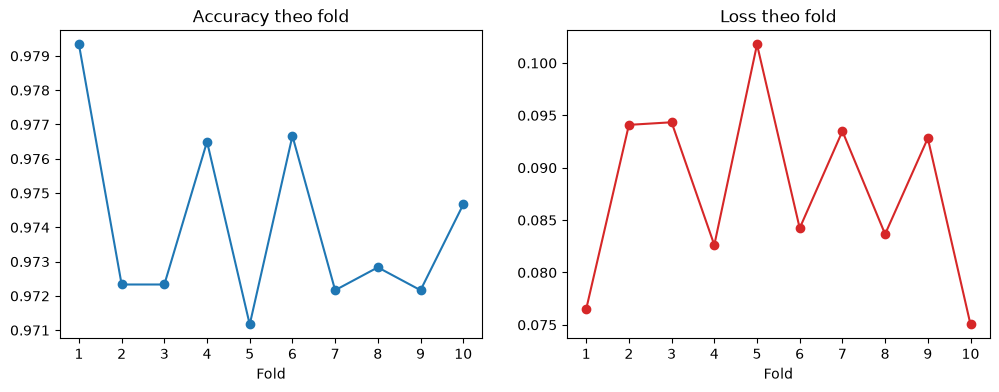

In [7]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# g) Biểu đồ accuracy, loss sau mỗi fold
folds = range(1, len(accuracy_per_fold) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(folds, accuracy_per_fold, "o-", color="tab:blue"); ax[0].set_title("Accuracy theo fold")
ax[0].set_xlabel("Fold"); ax[0].set_xticks(list(folds))
ax[1].plot(folds, loss_per_fold, "o-", color="tab:red"); ax[1].set_title("Loss theo fold")
ax[1].set_xlabel("Fold"); ax[1].set_xticks(list(folds))
plt.show()

In [8]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# h) Chọn mô hình có Accuracy tốt nhất giữa các fold và phân lớp tập test
index = np.argmax(accuracy_per_fold)
best_model = models[index]
print(f"Mô hình tốt nhất: fold {index + 1} (accuracy validation = {accuracy_per_fold[index]:.4f})")
y_pred = np.argmax(best_model.predict(test_images, verbose=0), axis=1)

Đinh Nhật Huyền Nhân - 6451071055
Mô hình tốt nhất: fold 1 (accuracy validation = 0.9793)


In [9]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# i) Accuracy trên tập test
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
print("Accuracy trên tập test:", accuracy_score(test_labels, y_pred))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy trên tập test: 0.9745


In [10]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# j) Precision, Recall, F1-score của từng lớp và trung bình
print(classification_report(test_labels, y_pred, digits=4))

Đinh Nhật Huyền Nhân - 6451071055
              precision    recall  f1-score   support

           0     0.9691    0.9918    0.9803       980
           1     0.9800    0.9912    0.9855      1135
           2     0.9681    0.9700    0.9690      1032
           3     0.9629    0.9772    0.9700      1010
           4     0.9639    0.9796    0.9717       982
           5     0.9886    0.9697    0.9791       892
           6     0.9812    0.9802    0.9807       958
           7     0.9821    0.9591    0.9705      1028
           8     0.9780    0.9589    0.9684       974
           9     0.9730    0.9653    0.9692      1009

    accuracy                         0.9745     10000
   macro avg     0.9747    0.9743    0.9744     10000
weighted avg     0.9746    0.9745    0.9745     10000



Đinh Nhật Huyền Nhân - 6451071055


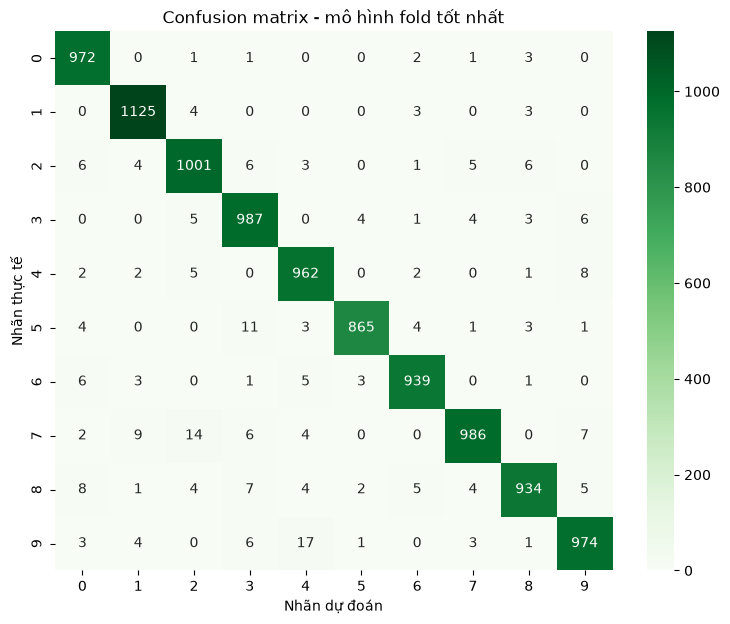

In [11]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# k) Confusion matrix bằng heat map
cm = confusion_matrix(test_labels, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.xlabel("Nhãn dự đoán"); plt.ylabel("Nhãn thực tế"); plt.title("Confusion matrix - mô hình fold tốt nhất")
plt.show()

Đinh Nhật Huyền Nhân - 6451071055
Ảnh 0: dự đoán = 7, thực tế = 7
Ảnh 1: dự đoán = 2, thực tế = 2
Ảnh 2: dự đoán = 1, thực tế = 1
Ảnh 3: dự đoán = 0, thực tế = 0


Ảnh 4: dự đoán = 4, thực tế = 4


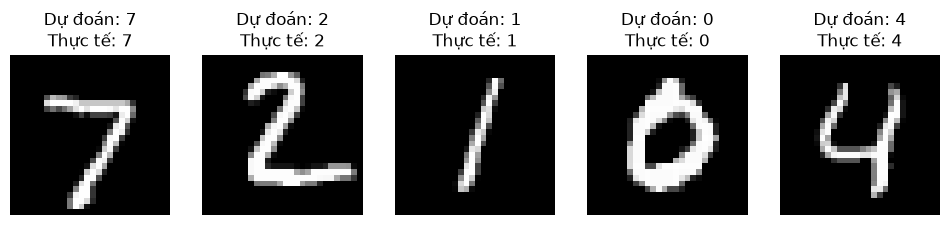

In [12]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# l) Kết quả phân lớp của 05 ảnh đầu tiên trong tập test
plt.figure(figsize=(12, 3))
for idx in range(5):
    img = np.expand_dims(test_images[idx], axis=0)
    du_doan = np.argmax(best_model.predict(img, verbose=0), axis=1)[0]
    print(f"Ảnh {idx}: dự đoán = {du_doan}, thực tế = {test_labels[idx]}")
    plt.subplot(1, 5, idx + 1)
    plt.imshow(test_images[idx], cmap="gray")
    plt.title(f"Dự đoán: {du_doan}\nThực tế: {test_labels[idx]}")
    plt.axis("off")
plt.show()